In [1]:
import pandas as pd
import numpy as np
import os
import sys
import pandas as pd
pd.options.mode.chained_assignment = None  # 完全关闭警告
import warnings
warnings.filterwarnings('ignore', category=pd.errors.SettingWithCopyWarning)


In [2]:
import pandas as pd
import numpy as np
import os
import sys
import pandas as pd
pd.options.mode.chained_assignment = None  # 完全关闭警告
import warnings
warnings.filterwarnings('ignore', category=pd.errors.SettingWithCopyWarning)


In [3]:
stead=pd.read_csv('/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.csv')

eqt=pd.read_csv('/home/yuan/code/SeisMoE'
                '/data/STEAD_Predict/STEAD_Eqtransformer/picks1.csv')

moe=pd.read_csv('/home/yuan/code/SeisMoE'
                '/data/STEAD_Predict/STEAD_Moe/picks_moe2.csv')

phasenet=pd.read_csv('/home/yuan/code/SeisMoE'
                     '/data/STEAD_Predict/STEAD_PhaseNet/picks1.csv')

ration=0.1
random_set=36


/tmp/ipykernel_753300/3297203204.py:1: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  stead=pd.read_csv('/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.csv')


# EQT

In [4]:
# phasenet=phasenet.loc[:100000,:]

# 提取 eqt 中的 file_name
file_names = eqt['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]
# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(eqt, filtered_stead, left_on='trace_name', right_on='trace_name')

# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_eqt = merged[['trace_name','trace_category', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_eqt

,trace_name,trace_category,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,BBGB.NC_20141015123814_EV,earthquake_local,400.0,782.0,400,798.0,0.0,-16.0
1,BZN.AZ_20140407165324_EV,earthquake_local,600.0,773.0,601,770.0,-1.0,3.0
2,GDXB.NC_20110602080423_EV,earthquake_local,396.0,479.0,399,466.0,-3.0,13.0
3,BRLK.AK_20150131212204_EV,earthquake_local,900.0,1909.0,900,1903.0,0.0,6.0
4,BZN.AZ_20140408035443_EV,earthquake_local,500.0,742.0,500,744.0,0.0,-2.0
...,...,...,...,...,...,...,...,...
75921,P19K.TA_20180226132701_EV,earthquake_local,500.0,1417.7,502,1434.0,-2.0,-16.3
75922,B203.PB_20121129210955_EV,earthquake_local,900.0,1123.0,901,1114.0,-1.0,9.0
75923,GO01.C_20131117125141_EV,earthquake_local,400.0,2383.0,401,2373.0,-1.0,10.0
75924,AIND.HV_20150626212841_EV,earthquake_local,900.0,1067.0,901,1049.0,-1.0,18.0


In [5]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_TP, 1, 0)
result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_eqt.loc[:, 'p_FN'] = np.where(abs(result_eqt['p_error']) > TP_threshold_FN, 1, 0)
result_eqt.loc[:, 's_FN'] = np.where(abs(result_eqt['s_error']) > TP_threshold_FN, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_eqt.loc[:, 'p_FP'] = np.where(result_eqt['trace_category'] == 'noise', 1, 0)
result_eqt.loc[:, 's_FP'] = np.where(result_eqt['trace_category'] == 'noise', 1, 0)

#计算stead的随机种子样本的noise个数
sampled_data = stead.sample(frac=ration, random_state=random_set)
sampled_data_count=len(stead.sample(frac=ration, random_state=random_set))
noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
earthquake_count=sampled_data_count - noise_count


#FP：噪声误报 + 未检测到的地震事件（除开噪声）
p_FP_count=result_eqt.loc[:, 'p_FP'].sum()+ earthquake_count - result_eqt.loc[:, 'p_TP'].sum() - result_eqt.loc[:, 'p_FN'].sum()
s_FP_count=result_eqt.loc[:, 's_FP'].sum()+ earthquake_count - result_eqt.loc[:, 's_TP'].sum() - result_eqt.loc[:, 's_FN'].sum()
#计算precision，recall，f1
p_TP= result_eqt['p_TP'].sum()
s_TP= result_eqt['s_TP'].sum()

p_FN= result_eqt['p_FN'].sum()
s_FN= result_eqt['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_eqt.loc[:, 'p_TP_mae'] = np.where(result_eqt['p_TP'] == 1, result_eqt['p_error'], 0)
result_eqt.loc[:, 's_TP_mae'] = np.where(result_eqt['s_TP'] == 1, result_eqt['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_eqt['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_eqt['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_eqt['p_TP_mae'].std() / 100
s_TP_std = result_eqt['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_eqt = pd.DataFrame({
    'EQT': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']] = (
    result_table_eqt.loc[result_table_eqt['EQT'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 74462
P-FP: 5417
P-FN: 1417
P-Precision: 0.9321849297061806
P-Recall: 0.9813255314382109
P-F1 Score: 0.9561242440195687
P-MAE: 0.014541624627326692
P-STD: 0.03690840807165783
S-TP: 69440
S-FP: 8125
S-FN: 3731
S-Precision: 0.895249145877651
S-Recall: 0.9490098536305367
S-F1 Score: 0.9213459293068677
S-MAE: 0.09987747188940092
S-STD: 0.13030455645370326


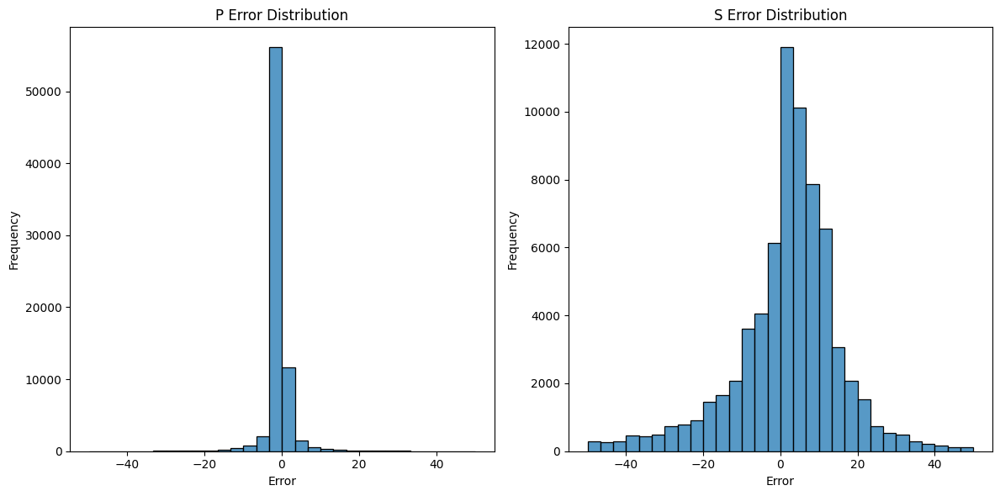

In [6]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_eqt[result_eqt['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_eqt[result_eqt['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# MOE

In [7]:


# phasenet=phasenet.loc[:130000,:]
# stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv')

In [8]:


# 提取 eqt 中的 file_name
file_names = moe['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(moe, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_moe = merged[['trace_name','trace_category', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_moe

,trace_name,trace_category,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,BBGB.NC_20141015123814_EV,earthquake_local,400.0,782.0,401,783.0,-1.0,-1.0
1,BZN.AZ_20140407165324_EV,earthquake_local,600.0,773.0,601,773.0,-1.0,0.0
2,GDXB.NC_20110602080423_EV,earthquake_local,396.0,479.0,400,472.0,-4.0,7.0
3,BRLK.AK_20150131212204_EV,earthquake_local,900.0,1909.0,906,1867.0,-6.0,42.0
4,BZN.AZ_20140408035443_EV,earthquake_local,500.0,742.0,500,746.0,0.0,-4.0
...,...,...,...,...,...,...,...,...
81342,B084.PB_20070501051124_EV,earthquake_local,400.0,646.0,401,645.0,-1.0,1.0
81343,B203.PB_20121129210955_EV,earthquake_local,900.0,1123.0,901,1119.0,-1.0,4.0
81344,GO01.C_20131117125141_EV,earthquake_local,400.0,2383.0,402,2371.0,-2.0,12.0
81345,AIND.HV_20150626212841_EV,earthquake_local,900.0,1067.0,902,1069.0,-2.0,-2.0


In [9]:
name=result_moe[(result_moe['p_error'] == 0) & (result_moe['s_error'] == 0)]['trace_name']
stead[(stead['trace_name'].isin(name))& (stead['source_magnitude']>0) & (stead['source_magnitude']<2)]



,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,source_magnitude_author,source_mechanism_strike_dip_rake,source_distance_deg,source_distance_km,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name
243909,HV,AHUD,EH,19.371567,-155.263462,1051.0,800.0,manual,0.00,4.55,...,NaN,NaN,0.2046,22.77,290.1,[17. 15.89999962 25.60000038],[[2446.]],2016/4/9 2:40:43,earthquake_local,AHUD.HV_20160409024041_EV
244255,HV,AHUD,EH,19.371567,-155.263462,1051.0,600.0,manual,0.68,3.29,...,NaN,NaN,0.1346,14.98,109.6,[14.89999962 18.39999962 22.20000076],[[2247.]],2016/9/28 19:05:12,earthquake_local,AHUD.HV_20160928190511_EV
249943,HV,AIND,HH,19.372067,-155.457228,1524.0,500.0,manual,0.66,5.85,...,NaN,NaN,0.1519,16.91,168.4,[32.79999924 33. 30.70000076],[[1507.]],2017/6/1 2:52:31,earthquake_local,AIND.HV_20170601025229_EV
250331,HV,AIND,HH,19.372067,-155.457228,1524.0,500.0,manual,0.00,8.63,...,NaN,NaN,0.4501,50.09,158.2,[22.5 25.20000076 27.89999962],[[2889.]],2017/9/22 15:28:03,earthquake_local,AIND.HV_20170922152801_EV
255828,HV,ALEP,EH,19.541178,-155.644036,2894.0,900.0,manual,0.63,7.11,...,NaN,NaN,0.3612,40.20,130.1,[24.89999962 27.39999962 24.20000076],[[2820.]],2016/1/17 16:51:44,earthquake_local,ALEP.HV_20160117165143_EV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1046521,AZ,PFO,HH,33.611700,-116.459400,1259.0,800.0,manual,0.58,4.12,...,CI,NaN,0.1790,19.90,275.7,[10.80000019 14.10000038 9.19999981],[[1634.]],2011/11/13 7:17:59,earthquake_local,PFO.AZ_20111113071757_EV
1047113,AZ,PFO,HH,33.611700,-116.459400,1259.0,600.0,manual,0.67,2.63,...,NaN,NaN,0.1212,13.48,178.7,[38.09999847 40.5 46.5 ],[[1403.]],2013/4/16 10:37:07,earthquake_local,PFO.AZ_20130416103705_EV
1047450,AZ,PFO,HH,33.611700,-116.459400,1259.0,600.0,manual,0.60,3.40,...,NaN,NaN,0.1289,14.33,226.7,[23.60000038 26. 27.5 ],[[1287.]],2014/3/9 4:38:53,earthquake_local,PFO.AZ_20140309043852_EV
1047458,AZ,PFO,HH,33.611700,-116.459400,1259.0,500.0,manual,0.63,3.14,...,NaN,NaN,0.1410,15.68,210.1,[17.5 18.20000076 18.29999924],[[1236.]],2014/3/18 10:18:11,earthquake_local,PFO.AZ_20140318101809_EV


In [10]:
import numpy as np

# 定义一个函数将字符串转为 float 数组
def parse_snr_string(snr_str):
    try:
        return np.fromstring(snr_str.strip('[]'), sep=' ')
    except:
        return np.array([])  # 避免出错时崩溃

# 把整列字符串转为数组列
snr_arrays = stead['snr_db'].apply(parse_snr_string)

# 创建布尔掩码：每个数组中所有元素都小于5
mask = snr_arrays.apply(lambda arr: np.all(arr < 10) & (len(arr) > 0))

# 筛选出满足条件的行
filtered_df = stead[mask & (stead['trace_name'].isin(name))]
filtered_df

,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,source_magnitude_author,source_mechanism_strike_dip_rake,source_distance_deg,source_distance_km,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name
274856,PB,B013,EH,47.813000,-122.910800,75.3,600.0,manual,0.95,3.73,...,UW,NaN,0.17730,19.70,151.9,[9.5 8. 7.30000019],[[1569.]],2011/7/10 11:37:28,earthquake_local,B013.PB_20110710113727_EV
371135,PB,B082,HH,33.598182,-116.596005,1374.8,700.0,manual,0.57,12.35,...,NaN,NaN,0.66690,74.16,309.1,[8.30000019 7.4000001 7.30000019],[[3199.]],2018/2/24 13:59:16,earthquake_local,B082.PB_20180224135915_EV
437676,PB,B087,EH,33.495500,-116.602667,1139.0,600.0,manual,0.59,4.37,...,CI,NaN,0.19370,21.54,329.6,[8. 9.69999981 9.5 ],[[2484.]],2012/6/2 10:15:49,earthquake_local,B087.PB_20120602101548_EV
442718,PB,B087,EH,33.495500,-116.602667,1139.0,900.0,manual,0.56,12.70,...,NaN,NaN,0.68250,75.90,338.9,[5.4000001 6. 5.4000001],[[3199.]],2013/10/31 19:26:12,earthquake_local,B087.PB_20131031192610_EV
472857,PB,B203,EH,46.169000,-122.333667,814.4,800.0,manual,0.93,2.62,...,NaN,NaN,0.11000,12.23,73.7,[8.39999962 9.60000038 8.30000019],[[2320.]],2014/7/11 11:24:46,earthquake_local,B203.PB_20140711112444_EV
551230,NC,BJOB,EH,36.610867,-121.314667,1052.0,800.0,manual,0.59,2.73,...,NC,NaN,0.13420,14.67,111.8,[6.5 7.19999981 2. ],[[2400.]],2011/2/6 11:32:15,earthquake_local,BJOB.NC_20110206113213_EV
570999,BK,BRK,HH,37.873520,-122.260990,49.4,600.0,manual,0.58,2.04,...,NaN,NaN,0.03522,3.92,77.7,[6.69999981 7. 9. ],[[1780.]],2018/2/26 14:15:44,earthquake_local,BRK.BK_20180226141542_EV
589377,AZ,BZN,HH,33.491500,-116.667000,1301.0,900.0,manual,0.64,3.68,...,NaN,NaN,0.14770,16.43,351.1,[7.5999999 9.69999981 9.5 ],[[1760.]],2015/11/5 19:43:27,earthquake_local,BZN.AZ_20151105194325_EV
642321,AZ,CRY,HH,33.565400,-116.737300,1128.0,800.0,manual,0.59,4.01,...,NaN,NaN,0.17520,19.49,114.4,[6.5999999 9.80000019 8.19999981],[[1756.]],2014/8/2 13:34:14,earthquake_local,CRY.AZ_20140802133413_EV
658000,BK,CVS,HH,38.345260,-122.458400,295.1,800.0,manual,0.00,9.95,...,NaN,NaN,0.50540,56.06,330.7,[6.19999981 3.4000001 7.0999999 ],[[3100.]],2013/8/31 20:39:29,earthquake_local,CVS.BK_20130831203928_EV


In [11]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_TP, 1, 0)
result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_moe.loc[:, 'p_FN'] = np.where(abs(result_moe['p_error']) > TP_threshold_FN, 1, 0)
result_moe.loc[:, 's_FN'] = np.where(abs(result_moe['s_error']) > TP_threshold_FN, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_moe.loc[:, 'p_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)
result_moe.loc[:, 's_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)

#计算stead的随机种子样本的noise个数
sampled_data = stead.sample(frac=ration, random_state=random_set)
sampled_data_count=len(stead.sample(frac=ration, random_state=random_set))
noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
earthquake_count=sampled_data_count - noise_count

#FP：噪声误报 + 未检测到的地震事件（除开噪声）
p_FP_count=result_moe.loc[:, 'p_FP'].sum()+ earthquake_count - result_moe.loc[:, 'p_TP'].sum() - result_moe.loc[:, 'p_FN'].sum()
s_FP_count=result_moe.loc[:, 's_FP'].sum()+ earthquake_count - result_moe.loc[:, 's_TP'].sum() - result_moe.loc[:, 's_FN'].sum()



#计算precision，recall，f1
p_TP= result_moe['p_TP'].sum()
s_TP= result_moe['s_TP'].sum()

p_FN= result_moe['p_FN'].sum()
s_FN= result_moe['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_moe.loc[:, 'p_TP_mae'] = np.where(result_moe['p_TP'] == 1, result_moe['p_error'], 0)
result_moe.loc[:, 's_TP_mae'] = np.where(result_moe['s_TP'] == 1, result_moe['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_moe['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_moe['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_moe['p_TP_mae'].std() / 100
s_TP_std = result_moe['s_TP_mae'].std() / 100


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_moe.loc[:, 'p_TP_mae'] = np.where(result_moe['p_TP'] == 1, result_moe['p_error'], 0)
result_moe.loc[:, 's_TP_mae'] = np.where(result_moe['s_TP'] == 1, result_moe['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_moe['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_moe['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_moe['p_TP_mae'].std() / 100
s_TP_std = result_moe['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_moe = pd.DataFrame({
    'Moe': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']] = (
    result_table_moe.loc[result_table_moe['Moe'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 79693
P-FP: 398
P-FN: 1406
P-Precision: 0.9950306526326304
P-Recall: 0.9826631647739184
P-F1 Score: 0.9888082387244868
P-MAE: 0.023564487470668687
P-STD: 0.04152675255335111
S-TP: 78257
S-FP: 430
S-FN: 2810
S-Precision: 0.9945353107883131
S-Recall: 0.9653373135801251
S-F1 Score: 0.9797188176821864
S-MAE: 0.07514721368056533
S-STD: 0.11384550613880601


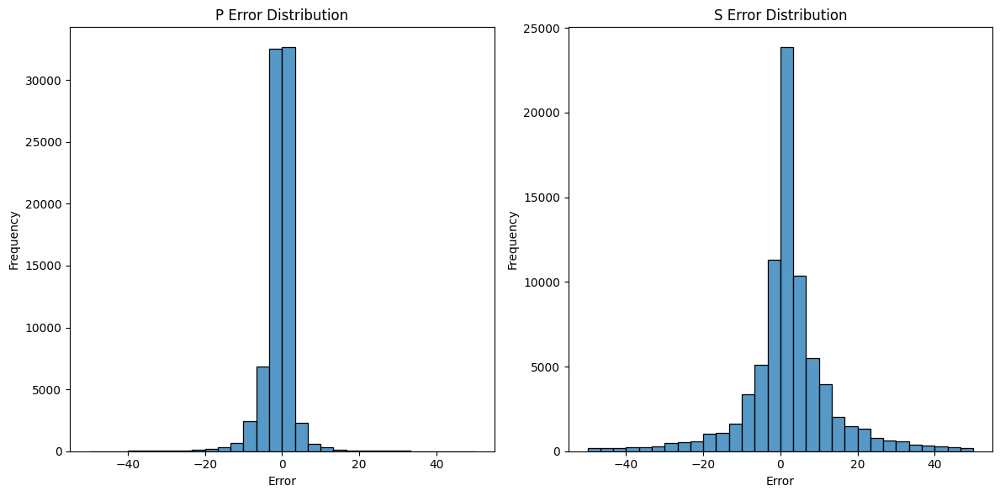

In [12]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_moe[result_moe['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_moe[result_moe['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# PhaseNet

In [13]:

# phasenet=phasenet.loc[:170000,:]
# stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv')

In [14]:


# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_phasenet = merged[['trace_name','trace_category', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_phasenet

,trace_name,trace_category,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,BBGB.NC_20141015123814_EV,earthquake_local,400.0,782.0,403,792.0,-3.0,-10.0
1,BZN.AZ_20140407165324_EV,earthquake_local,600.0,773.0,603,777.0,-3.0,-4.0
2,CMW.NC_201711200538_NO,noise,NaN,NaN,923,NaN,NaN,NaN
3,GDXB.NC_20110602080423_EV,earthquake_local,396.0,479.0,398,482.0,-2.0,-3.0
4,BRLK.AK_20150131212204_EV,earthquake_local,900.0,1909.0,918,1861.0,-18.0,48.0
...,...,...,...,...,...,...,...,...
86835,B084.PB_20070501051124_EV,earthquake_local,400.0,646.0,404,647.0,-4.0,-1.0
86836,B203.PB_20121129210955_EV,earthquake_local,900.0,1123.0,903,1125.0,-3.0,-2.0
86837,GO01.C_20131117125141_EV,earthquake_local,400.0,2383.0,406,2383.0,-6.0,0.0
86838,AIND.HV_20150626212841_EV,earthquake_local,900.0,1067.0,904,1073.0,-4.0,-6.0


In [15]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 50
TP_threshold_FN= 50
result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_TP, 1, 0)
result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_phasenet.loc[:, 'p_FN'] = np.where(abs(result_phasenet['p_error']) > TP_threshold_FN, 1, 0)
result_phasenet.loc[:, 's_FN'] = np.where(abs(result_phasenet['s_error']) > TP_threshold_FN, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_phasenet.loc[:, 'p_FP'] = np.where(result_phasenet['trace_category'] == 'noise', 1, 0)
result_phasenet.loc[:, 's_FP'] = np.where(result_phasenet['trace_category'] == 'noise', 1, 0)

#计算stead的随机种子样本的noise个数
sampled_data = stead.sample(frac=ration, random_state=random_set)
sampled_data_count=len(stead.sample(frac=ration, random_state=random_set))
noise_count = len(sampled_data[sampled_data['trace_category'] == 'noise'])
earthquake_count=sampled_data_count - noise_count


#FP：噪声误报 + 未检测到的地震事件（除开噪声）
p_FP_count=result_phasenet.loc[:, 'p_FP'].sum()+ earthquake_count - result_phasenet.loc[:, 'p_TP'].sum() - result_phasenet.loc[:, 'p_FN'].sum()
s_FP_count=result_phasenet.loc[:, 's_FP'].sum()+ earthquake_count - result_phasenet.loc[:, 's_TP'].sum() - result_phasenet.loc[:, 's_FN'].sum()


#计算precision，recall，f1
p_TP= result_phasenet['p_TP'].sum()
s_TP= result_phasenet['s_TP'].sum()

p_FN= result_phasenet['p_FN'].sum()
s_FN= result_phasenet['s_FN'].sum()

# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_phasenet.loc[:, 'p_TP_mae'] = np.where(result_phasenet['p_TP'] == 1, result_phasenet['p_error'], 0)
result_phasenet.loc[:, 's_TP_mae'] = np.where(result_phasenet['s_TP'] == 1, result_phasenet['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_phasenet['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_phasenet['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_phasenet['p_TP_mae'].std() / 100
s_TP_std = result_phasenet['s_TP_mae'].std() / 100

# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_phasenet.loc[:, 'p_TP_mae'] = np.where(result_phasenet['p_TP'] == 1, result_phasenet['p_error'], 0)
result_phasenet.loc[:, 's_TP_mae'] = np.where(result_phasenet['s_TP'] == 1, result_phasenet['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_phasenet['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_phasenet['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_phasenet['p_TP_mae'].std() / 100
s_TP_std = result_phasenet['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)

#将结果做成一个表格
result_table_phasenet = pd.DataFrame({
    'PhaseNet': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})

# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']] = (
    result_table_phasenet.loc[result_table_phasenet['PhaseNet'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 79029
P-FP: 5831
P-FN: 2100
P-Precision: 0.9312868253594155
P-Recall: 0.9741152978589653
P-F1 Score: 0.9522197254034905
P-MAE: 0.05628482245757885
P-STD: 0.07074465932649882
S-TP: 77881
S-FP: 5999
S-FN: 3080
S-Precision: 0.9284811635670005
S-Recall: 0.9619569916379491
S-F1 Score: 0.9449226830703527
S-MAE: 0.07484632554795136
S-STD: 0.10203526419888885


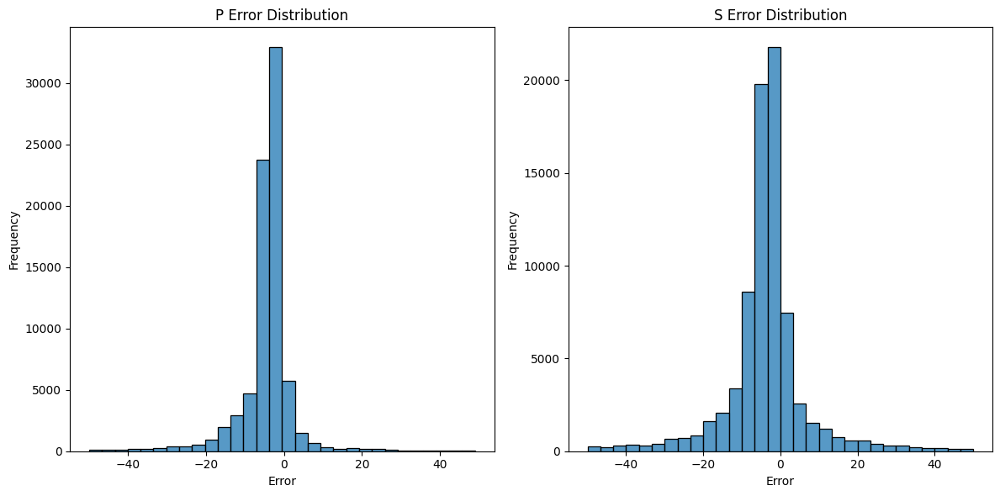

In [16]:

import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
data=result_phasenet[result_phasenet['p_TP'] == 1]['p_error']

sns.histplot(result_phasenet[result_phasenet['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_phasenet[result_phasenet['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# Results

In [17]:
import pandas as pd

# 1) 以 EQT 表举例
df_eqt = result_table_eqt.set_index('EQT')
# 将原本的列 ['P', 'S'] 改成多层索引：最上层 'EQT'，第二层保持原列名
df_eqt.columns = pd.MultiIndex.from_tuples([('EQT', col) for col in df_eqt.columns])

# 2) Moe 表同理
df_moe = result_table_moe.set_index('Moe')
df_moe.columns = pd.MultiIndex.from_tuples([('Moe', col) for col in df_moe.columns])

# 3) PhaseNet 表
df_phasenet = result_table_phasenet.set_index('PhaseNet')
df_phasenet.columns = pd.MultiIndex.from_tuples([('PhaseNet', col) for col in df_phasenet.columns])

# 4) 横向合并
df_multi = pd.concat([df_moe,df_eqt, df_phasenet], axis=1)

print('-------------------------------------stead--------------------------------------------')
df_multi


-------------------------------------stead--------------------------------------------


Moe                         EQT                \
                      P             S             P             S   
TP         79693.000000  78257.000000  74462.000000  69440.000000   
FP           398.000000    430.000000   5417.000000   8125.000000   
FN          1406.000000   2810.000000   1417.000000   3731.000000   
Precision      0.995031      0.994535      0.932185      0.895249   
Recall         0.982663      0.965337      0.981326      0.949010   
F1 Score       0.988808      0.979719      0.956124      0.921346   
MAE            0.023564      0.075147      0.014542      0.099877   
STD            0.041527      0.113846      0.036908      0.130305   

               PhaseNet                
                      P             S  
TP         79029.000000  77881.000000  
FP          5831.000000   5999.000000  
FN          2100.000000   3080.000000  
Precision      0.931287      0.928481  
Recall         0.974115      0.961957  
F1 Score       0.952220      0.944923  
MAE            0.056285      0.074846  
STD            0.070745      0.102035

| <br/> | Moe<br/>P | Moe<br/>S | EQT<br/>P | EQT<br/>S | PhaseNet<br/>P | PhaseNet<br/>S |
| :--- | :--- | :--- | :--- | :--- | :--- |:---------------|
| TP | 79693.000000 | 78257.000000 | 74462.000000 | 69440.000000 | 79029.000000 | 77881.000000   |
| FP | 398.000000 | 430.000000 | 5417.000000 | 8125.000000 | 5831.000000 | 5999.000000    |
| FN | 1406.000000 | 2810.000000 | 1417.000000 | 3731.000000 | 2100.000000 | 3080.000000    |
| Precision | 0.995031 | 0.994535 | 0.932185 | 0.895249 | 0.931287 | 0.928481       |
| Recall | 0.982663 | 0.965337 | 0.981326 | 0.949010 | 0.974115 | 0.961957       |
| F1 Score | 0.988808 | 0.979719 | 0.956124 | 0.921346 | 0.952220 | 0.944923       |
| MAE |0.014542  | 0.075147 |0.023564  | 0.099877 | 0.056285 | 0.078846       |
| STD |0.036908  |  0.102035|0.041527  |0.130305  | 0.070745 | 0.113846       |


# EQT figure

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.cm as cm
import matplotlib.colors as colors
import scienceplots
import os
from matplotlib.ticker import FuncFormatter

base_fontsize = 50

plt.rcParams.update({
    'font.size': base_fontsize,
    'axes.titlesize': base_fontsize * 1.0,
    'axes.labelsize': base_fontsize * 0.9,
    'xtick.labelsize': base_fontsize * 0.7,
    'ytick.labelsize': base_fontsize * 0.7,
    'legend.fontsize': base_fontsize * 0.8,
    'figure.titlesize': base_fontsize * 1.2
})

cmap_pos = plt.get_cmap('viridis').reversed()
cmap_neg = plt.get_cmap('viridis')

def plot_error_distribution(data, title, xlabel, mae, sigma, store_path, filename):
    with plt.style.context(['science', 'ieee']):
        fig, ax = plt.subplots(figsize=(10, 6))
        counts, bins = np.histogram(data, bins=30)
        max_pos, min_neg = 0.5, -0.5
        norm_pos = colors.Normalize(vmin=0, vmax=max_pos)
        norm_neg = colors.Normalize(vmin=min_neg, vmax=0)

        for count, left, right in zip(counts, bins[:-1], bins[1:]):
            center = 0.5 * (left + right)
            color = cmap_pos(norm_pos(center)) if center >= 0 else cmap_neg(norm_neg(center))
            ax.bar(center, count, width=right - left, color=color, align='center')

        ax.set_title(title, pad=20)
        # ax.set_xlabel(xlabel, labelpad=15)
        ax.set_ylim(0, counts.max() * 1.1)
        ax.set_xticks([])

        # 设置 y 轴的显示格式
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y / 1e3:.1f}' if y < 1000 else f'{y / 1e3:.0f}'))

        # 在 y 轴顶部添加 ×10³
        ax.text(0, 1.01, r'$\times 10^3$',
                transform=ax.transAxes,
                fontsize=base_fontsize * 0.7,
                ha='left', va='bottom')

        # 添加统计信息文本框
        stats_text = f'$\\mathrm{{MAE}}={mae}\\,\\mathrm{{s}}$\n$\\sigma={sigma}\\,\\mathrm{{s}}$'
        ax.text(0.95, 0.95, stats_text,
                transform=ax.transAxes,
                ha='right', va='top',
                fontsize=base_fontsize * 0.6,
                bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=10))

        plt.tight_layout()
        path = os.path.join(store_path, filename)
        plt.savefig(path, dpi=600, bbox_inches='tight')
        plt.show()


/tmp/ipykernel_753300/3497951265.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_pos = cm.get_cmap('viridis').reversed()
/tmp/ipykernel_753300/3497951265.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_neg = cm.get_cmap('viridis')


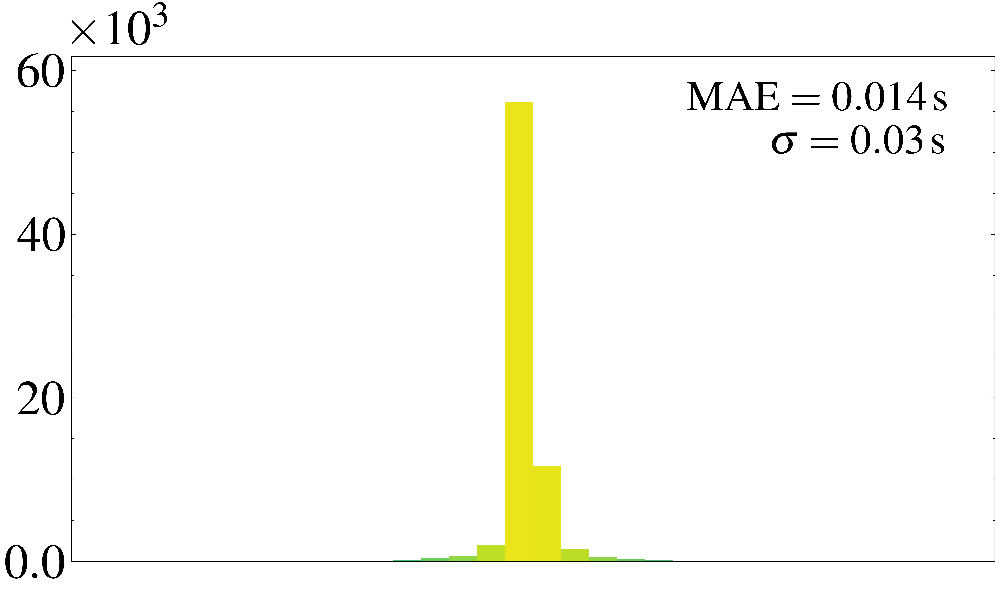

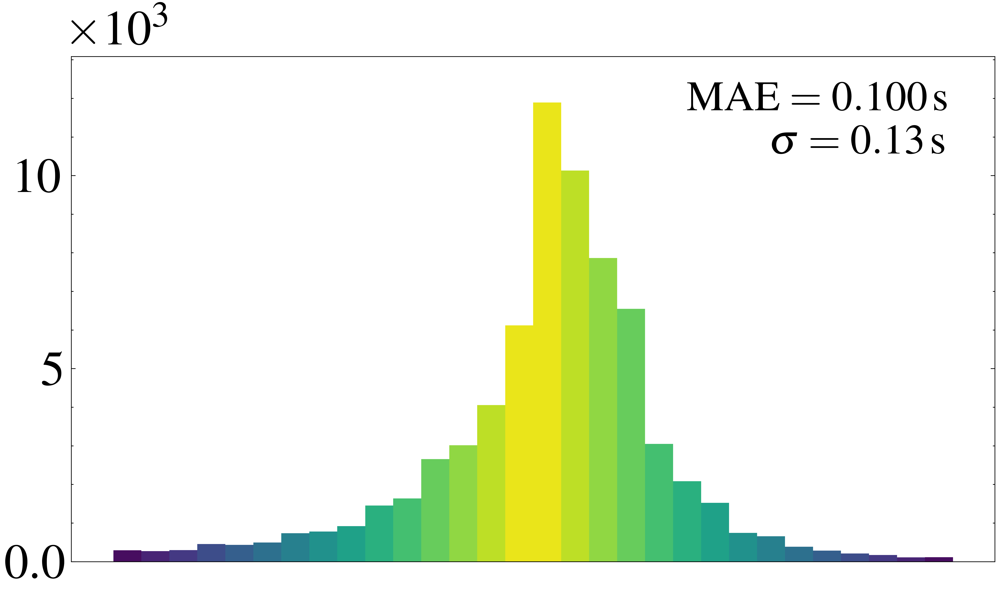

In [19]:

# 绘制P波
data_p = result_eqt[result_eqt['p_TP'] == 1]['p_error']/100
plot_error_distribution(data_p,
                      '',
                      'SeisMoe P Picking Error (s)',
                      '0.014', '0.03',
                      '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
                      'SeisMoe_P_error_distribution.svg')

# 绘制S波
data_s = result_eqt[result_eqt['s_TP'] == 1]['s_error']/100
plot_error_distribution(data_s,
                      '',
                      'EQTransformer S Picking Error (s)',
                      '0.100', '0.13',
                        '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
                      'EQTransformer_S_error_distribution.svg')

# Moe Figure

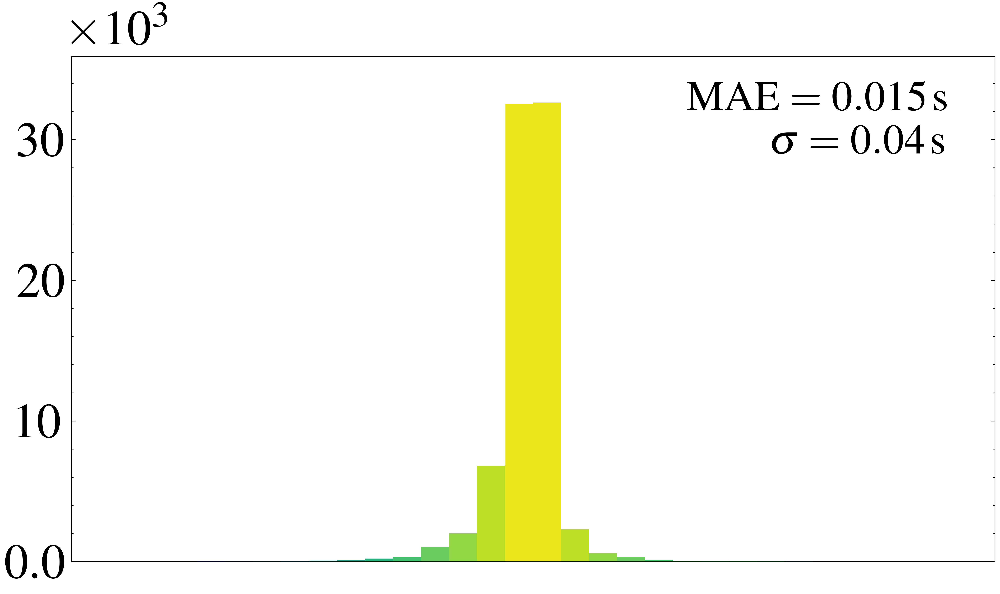

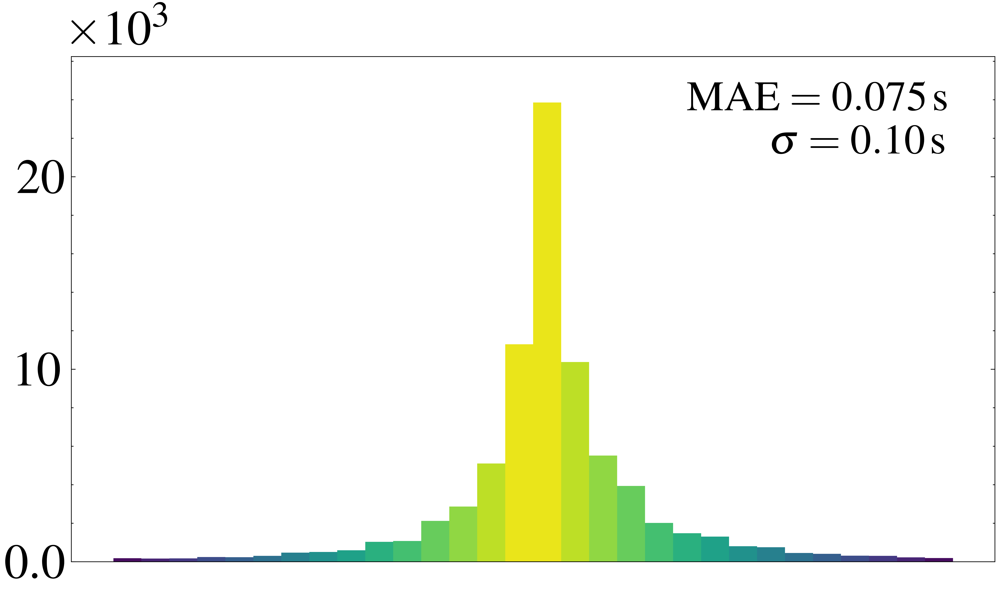

In [20]:

# 绘制P波
data_p = result_moe[result_moe['p_TP'] == 1]['p_error']/100
plot_error_distribution(data_p,
                      '',
                      'EQTransformer P Picking Error (s)',
                      '0.015', '0.04',
                        '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
                      'EQTransformer_P_error_distribution.svg')

# 绘制S波
data_s = result_moe[result_moe['s_TP'] == 1]['s_error']/100
plot_error_distribution(data_s,
                      '',
                      'SeisMoe S Picking Error (s)',
                      '0.075', '0.10',
                        '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
                      'SeisMoe_S_error_distribution.svg')

# PhaseNet Figure

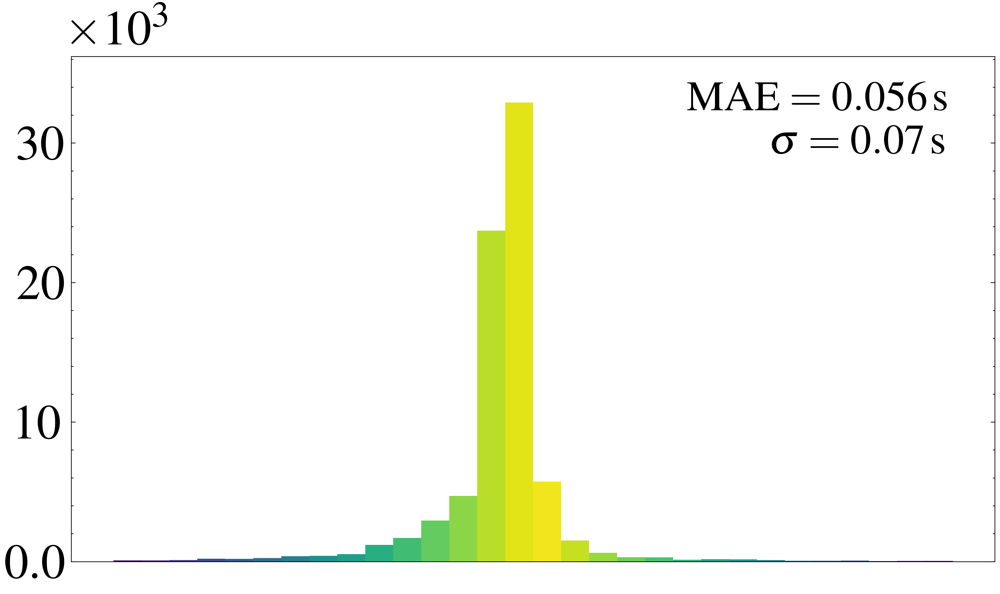

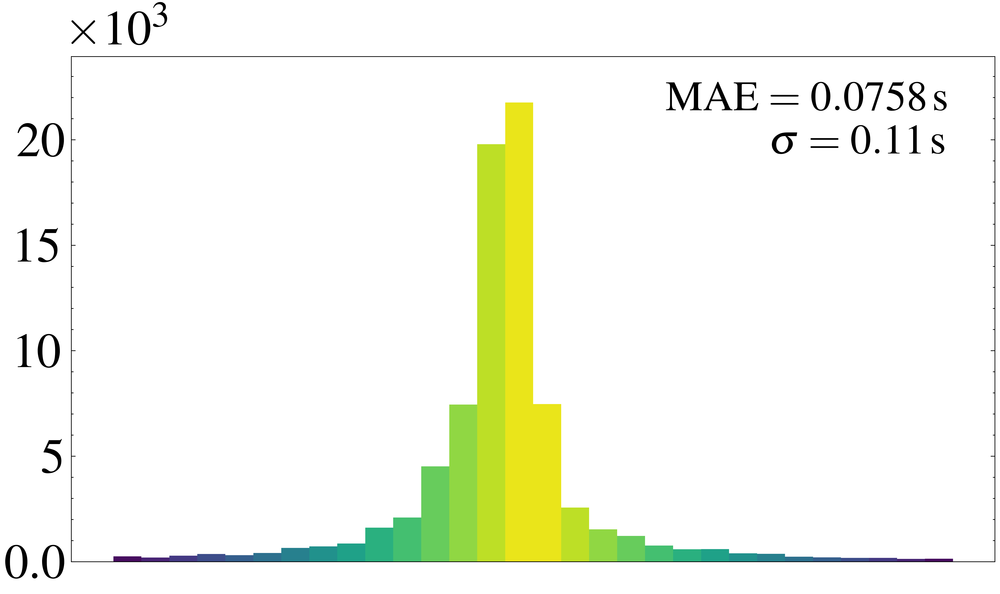

In [21]:

# 绘制P波
data_p = result_phasenet[result_phasenet['p_TP'] == 1]['p_error']/100
plot_error_distribution(data_p,
                      '',
                      'PhaseNet P Picking Error (s)',
                      '0.056', '0.07',
                        '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
                      'PhaseNet_P_error_distribution.svg')

# 绘制S波
data_s = result_phasenet[result_phasenet['s_TP'] == 1]['s_error']/100
plot_error_distribution(data_s,
                      '',
                      'PhaseNet S Picking Error (s)',
                      '0.0758', '0.11',
                        '/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
                      'PhaseNet_S_error_distribution.svg')

# figure

In [22]:
# import h5py
# import pandas as pd
# import matplotlib.pyplot as plt
# import os
#
# # 输入路径
# hd = '/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.hdf5'
# output_dir = '/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/Figure/output_waveforms_STEAD/'
# os.makedirs(output_dir, exist_ok=True)
#
# # ===== 读取数据并求交集 =====
# # 筛选 P/S 都为 TP 的 trace_name
# eqt_tp = result_eqt[(result_eqt['p_TP'] == 1) & (result_eqt['s_TP'] == 1)]['trace_name']
# moe_tp = result_moe[(result_moe['p_TP'] == 1) & (result_moe['s_TP'] == 1)]['trace_name']
# phasenet_tp = result_phasenet[(result_phasenet['p_TP'] == 1) & (result_phasenet['s_TP'] == 1)]['trace_name']
# common_traces = set(eqt_tp) & set(moe_tp) & set(phasenet_tp)
#
# # 筛选出三组数据对应的行
# df_eqt = result_eqt[result_eqt['trace_name'].isin(common_traces)].copy()
# df_moe = result_moe[result_moe['trace_name'].isin(common_traces)].copy()
# df_phasenet = result_phasenet[result_phasenet['trace_name'].isin(common_traces)].copy()
#
# # 设置索引，便于 trace_name 访问
# moe_dict = df_moe.set_index('trace_name')[['p_idx', 's_idx']].to_dict('index')
# phasenet_dict = df_phasenet.set_index('trace_name')[['p_idx', 's_idx']].to_dict('index')
# df_eqt=df_eqt.sample(n=100,random_state=42).copy()
# # ===== 读取波形并绘图 =====
# with h5py.File(hd, 'r') as f:
#     for i, row in df_eqt.iterrows():
#         if row['trace_category'] == 'noise':
#             continue
#
#         trace_name = row['trace_name']
#         try:
#             data = f['data'][trace_name][()]  # shape: (3, 6000)
#         except KeyError:
#             print(f"[WARN] Missing trace: {trace_name}")
#             continue
#
#         z, n, e = data[:,0], data[:,1], data[:,2]
#
#         p_arrival = row['p_arrival_sample']
#         s_arrival = row['s_arrival_sample']
#         p_eqt = row['p_idx']
#         s_eqt = row['s_idx']
#         p_moe = moe_dict[trace_name]['p_idx']
#         s_moe = moe_dict[trace_name]['s_idx']
#         p_phase = phasenet_dict[trace_name]['p_idx']
#         s_phase = phasenet_dict[trace_name]['s_idx']
#
#         fig, axs = plt.subplots(5, 1, figsize=(12, 10), sharex=False)
#         components = [z, n, e]
#         labels = ['Z', 'N', 'E']
#
#         for idx, (ax, comp, label) in enumerate(zip(axs[:3], components, labels)):
#             ax.plot(comp, label=f'{label} component')
#
#             # 到时标注
#             ax.axvline(p_arrival, color='green', linestyle='--', label='P Arrival')
#             ax.axvline(s_arrival, color='blue', linestyle='--', label='S Arrival')
#             ax.axvline(p_eqt, color='red', linestyle=':', label='EQT P')
#             ax.axvline(s_eqt, color='purple', linestyle=':', label='EQT S')
#             ax.axvline(p_moe, color='orange', linestyle=':', label='Moe P')
#             ax.axvline(s_moe, color='brown', linestyle=':', label='Moe S')
#             ax.axvline(p_phase, color='pink', linestyle='--', label='PhaseNet P')
#             ax.axvline(s_phase, color='cyan', linestyle='--', label='PhaseNet S')
#
#             ax.set_ylabel(label)
#             ax.legend(loc='upper right', fontsize=8)
#
#         # 第四图：P 波放大图（Z）
#         start_p = max(0, int(min(p_arrival, p_eqt, p_moe, p_phase) - 50))
#         end_p = min(6000, int(max(p_arrival, p_eqt, p_moe, p_phase) + 50))
#         axs[3].plot(z[start_p:end_p], label='Z (P Zoom)')
#         axs[3].axvline(p_arrival - start_p, color='black', linestyle='--', label='P Arrival')
#         axs[3].axvline(p_eqt - start_p, color='green', linestyle=':', label='EQT P')
#         axs[3].axvline(p_moe - start_p, color='red', linestyle=':', label='Moe P')
#         axs[3].axvline(p_phase - start_p, color='orange', linestyle='--', label='PhaseNet P')
#         axs[3].legend(loc='upper right', fontsize=8)
#         axs[3].set_ylabel('Z (P Zoom)')
#
#         # 第五图：S 波放大图（Z）
#         start_s = max(0, int(min(s_arrival, s_eqt, s_moe, s_phase) - 50))
#         end_s = min(6000, int(max(s_arrival, s_eqt, s_moe, s_phase) + 50))
#         axs[4].plot(z[start_s:end_s], label='Z (S Zoom)')
#         axs[4].axvline(s_arrival - start_s, color='black', linestyle='--', label='S Arrival')
#         axs[4].axvline(s_eqt - start_s, color='green', linestyle=':', label='EQT S')
#         axs[4].axvline(s_moe - start_s, color='red', linestyle=':', label='Moe S')
#         axs[4].axvline(s_phase - start_s, color='orange', linestyle='--', label='PhaseNet S')
#         axs[4].legend(loc='upper right', fontsize=8)
#         axs[4].set_ylabel('Z (S Zoom)')
#
#         # 保存图像
#         fig.suptitle(f'Trace: {trace_name}', fontsize=14)
#         plt.tight_layout(rect=[0, 0.03, 1, 0.95])
#         out_path = os.path.join(output_dir, f'{trace_name}.png')
#         plt.savefig(out_path)
#         plt.close(fig)


# STEAD Samples Figure

## Moe Predict

In [23]:
# trace_name='GDXB.NC_20150501225411_EV'#GDXB.NC_20150501225411_EV_M0.56_SNR_22.5
# trace_name='GO02.C_20130925131520_EV'# GO02.C_20130925131520_EV_M5.3_SNR_71
# trace_name='M02C.TA_20131011230555_EV'# M02C.TA_20131011230555_EV_M5.2_SNR_75
# trace_name='B004.PB_20140905132114_EV'# B004.PB_20140905132114_EV_M0.42_SNR_7.1
# trace_name='B013.PB_20110710113727_EV'# B013.PB_20110710113727_EV_M0.4_SNR_8.2

In [24]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def Moe_predict(trace_name):
        import sys
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="1"
        # 将自定义模型文件所在目录加入路径
        sys.path.append("/home/yuan/code/SeisMoE/src")
        # 导入自定义模型文件，假设其中包含与 seisbench EQTransformer 接口相同的模型类
        from model_moe_gpt_PS2_CPU import IMG1

        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测"""
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            best_p = p_peaks[p_props['peak_heights'].argmax()] if len(p_peaks) > 0 else None
            best_s = None

            if best_p is not None:
                for s in s_peaks:
                    if 0 < (s - best_p) < 6000:  # 60秒窗口(100Hz采样)
                        best_s = s
                        break

            return best_p, best_s, p_props['peak_heights'].max() if best_p is not None else None, \
                   s_props['peak_heights'][s_peaks.tolist().index(best_s)] if best_s is not None else None



        def normalize_data(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)




        hdf5_path="/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.hdf5"
        p_thresh=0.1,
        s_thresh=0.1
        trace_names = trace_name



        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            dataset = f['data'].get(trace_name)
            normalized = dataset[:].T  # shape: (3, n_samples)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data(normalized, 'std')
        data=torch.from_numpy(normalized.T).unsqueeze(0)


        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = IMG1().to(device)
        model.load_state_dict(torch.load("/home/yuan/code/SeisMoE/models/Model_Store/CPU2_moe/best_model.pth",map_location=device))

        model.eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output,_ = model_predict(model, data)
        moe_p_prob= output[0].cpu()
        moe_s_prob= output[1].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(moe_p_prob, moe_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))

        # output_csv = os.path.join(output_dir, 'picks——moe2.csv')
        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])

        moe_p=results['p_idx'].values[0]
        moe_s=results['s_idx'].values[0]
        moe_pc=results['p_conf'].values[0]
        moe_sc=results['s_conf'].values[0]


        print(f"Moe P index:{results['p_idx'].values[0]}")
        print(f"Moe S index:{results['s_idx'].values[0]}")
        print(f"Moe P confidence:{results['p_conf'].values[0]}")
        print(f"Moe S confidence:{results['s_conf'].values[0]}")

        return moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob





## Eqtransformer Predict

In [25]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def EQT_Predict(trace_name):
        import os
        import random
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        import seisbench.models as sbm
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        import h5py
        import numpy as np
        import torch
        from torch.utils.data import Dataset
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="2"
        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测，
            逻辑：仅根据 p_arr 中幅值最高的峰确定 P，
            然后在 P 后面 6000 个采样点内，从 s_arr 中选择幅值最高的峰作为 S。
            """
            # 对 p_arr 和 s_arr 分别进行峰值检测
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            # 选择 p_arr 中最高的峰作为 P
            if len(p_peaks) > 0:
                best_p_index = np.argmax(p_props['peak_heights'])
                best_p = p_peaks[best_p_index]
                p_conf = p_props['peak_heights'][best_p_index]
            else:
                best_p = None
                p_conf = None

            best_s = None
            s_conf = None

            if best_p is not None:
                # 筛选出在 P 后且距离 P 小于 6000 个采样点的所有 S 峰
                valid_s_indices = [i for i, s in enumerate(s_peaks) if s > best_p and (s - best_p) < 6000]
                if valid_s_indices:
                    valid_s_peaks = s_peaks[valid_s_indices]
                    valid_s_props = s_props['peak_heights'][valid_s_indices]
                    best_s_idx = np.argmax(valid_s_props)
                    best_s = valid_s_peaks[best_s_idx]
                    s_conf = valid_s_props[best_s_idx]
            return best_p, best_s, p_conf, s_conf


        def normalize_data(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)

        # def main(trace_name, hdf5_path, p_thresh=0.3, s_thresh=0.3, batch_size=2048):



        hdf5_path=r'/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.hdf5'
        p_thresh=0.1
        s_thresh=0.1
        trace_names = trace_name

        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            dataset = f['data'].get(trace_name)
            normalized = dataset[:].T  # shape: (3, n_samples)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data(normalized, 'std')
        data=torch.from_numpy(normalized).unsqueeze(0)

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = sbm.EQTransformer.from_pretrained("original").to(device).eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output= model_predict(model, data)
        eqt_p_prob= output[1].cpu()
        eqt_s_prob= output[2].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(eqt_p_prob, eqt_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))


        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])
        eqt_p=results['p_idx'].values[0]
        eqt_s=results['s_idx'].values[0]
        eqt_pc=results['p_conf'].values[0]
        eqt_sc=results['s_conf'].values[0]
        # print(f"****拾取到的事件数：{len(results)}")
        print(f"eqt P index:{results['p_idx'].values[0]}")
        print(f"eqt S index:{results['s_idx'].values[0]}")
        print(f"eqt P confidence:{results['p_conf'].values[0]}")
        print(f"eqt S confidence:{results['s_conf'].values[0]}")

        return eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob


## PhaseNet Predict

In [26]:
    #!/usr/bin/env python
    # -*- coding: utf-8 -*-
def PhaseNet_predict(trace_name):
        import os
        import random
        import h5py
        import numpy as np
        import pandas as pd
        import torch
        from scipy.signal import find_peaks
        from torch.utils.data import Dataset, DataLoader
        import seisbench.models as sbm
        from tqdm import tqdm
        from datetime import datetime, timedelta
        import multiprocessing as mp
        import h5py
        import numpy as np
        import torch
        from torch.utils.data import Dataset
        from scipy.signal import resample,butter,filtfilt
        import os
        os.environ["CUDA_VISIBLE_DEVICES"]="2"
        def detect_phases(p_arr, s_arr, p_thresh=0.3, s_thresh=0.3):
            """使用 scipy.signal.find_peaks 实现相位检测，
            逻辑：仅根据 p_arr 中幅值最高的峰确定 P，
            然后在 P 后面 6000 个采样点内，从 s_arr 中选择幅值最高的峰作为 S。
            """
            # 对 p_arr 和 s_arr 分别进行峰值检测
            p_peaks, p_props = find_peaks(p_arr, height=p_thresh, distance=100)
            s_peaks, s_props = find_peaks(s_arr, height=s_thresh, distance=100)

            # 选择 p_arr 中最高的峰作为 P
            if len(p_peaks) > 0:
                best_p_index = np.argmax(p_props['peak_heights'])
                best_p = p_peaks[best_p_index]
                p_conf = p_props['peak_heights'][best_p_index]
            else:
                best_p = None
                p_conf = None

            best_s = None
            s_conf = None

            if best_p is not None:
                # 筛选出在 P 后且距离 P 小于 6000 个采样点的所有 S 峰
                valid_s_indices = [i for i, s in enumerate(s_peaks) if s > best_p and (s - best_p) < 6000]
                if valid_s_indices:
                    valid_s_peaks = s_peaks[valid_s_indices]
                    valid_s_props = s_props['peak_heights'][valid_s_indices]
                    best_s_idx = np.argmax(valid_s_props)
                    best_s = valid_s_peaks[best_s_idx]
                    s_conf = valid_s_props[best_s_idx]
            return best_p, best_s, p_conf, s_conf


        def normalize_data(data, mode='std'):
            data -= np.mean(data, axis=1, keepdims=True)

            if mode == 'std':
                std_val = np.std(data, axis=1, keepdims=True)
                std_val[std_val == 0] = 1.0
                data /= std_val
            elif mode == 'max':
                max_val = np.max(np.abs(data), axis=1, keepdims=True)
                max_val[max_val == 0] = 1.0
                data /= max_val
            else:
                raise ValueError(f"Unsupported norm_mode: {mode}")
            return data


        def bandpass_filter(data, lowcut, highcut, fs, order=4):
            """
            对每个通道数据进行带通滤波。
            data: 形状为 (3, T)
            lowcut, highcut: 滤波器截止频率
            fs: 采样率
            """
            nyquist = 0.5 * fs
            low = lowcut / nyquist
            high = highcut / nyquist
            b, a = butter(order, [low, high], btype='band')

            filtered = np.zeros_like(data)
            for ch in range(data.shape[0]):
                filtered[ch] = filtfilt(b, a, data[ch])
            return filtered



        def model_predict(model, data: torch.Tensor):
            with torch.no_grad():
                return model(data)

        # def main(trace_name, hdf5_path, p_thresh=0.3, s_thresh=0.3, batch_size=2048):



        hdf5_path=r'/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.hdf5'
        p_thresh=0.1
        s_thresh=0.1
        trace_names = trace_name

        with h5py.File(hdf5_path, 'r') as f:
            if 'data' not in f:
                raise KeyError("HDF5文件中缺少'data'组")

            dataset = f['data'].get(trace_name)
            normalized = dataset[:].T  # shape: (3, n_samples)
        # normalized = (normalized - np.mean(normalized, axis=0)) / (np.std(normalized, axis=0) + 1e-10)
        # 滤波：1-45Hz 带通滤波
        normalized = bandpass_filter(normalized, lowcut=1.0, highcut=40.0, fs=100)
        #
        # # 标准化
        normalized = normalize_data(normalized, 'std')
        data=torch.from_numpy(normalized).unsqueeze(0)

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

        # 加载自定义模型
        # 此处假设模型文件 model_moe_gpt_PS3_CPU.py 中定义的类名为 EQTransformer
        model = sbm.PhaseNet.from_pretrained("original").to(device).eval()

        results = []
        data = data.to(device)
        # 进行模型推理，假设返回格式与 seisbench 的 EQTransformer 一致，
        # 其中 output[1] 为 P 概率，output[2] 为 S 概率
        output= model_predict(model, data)
        phasenet_p_prob= output[:, 1, :].cpu()
        phasenet_s_prob= output[:, 2, :].cpu()

        for i, (p_arr, s_arr) in enumerate(zip(phasenet_p_prob, phasenet_s_prob)):
            p_idx, s_idx, p_conf, s_conf = detect_phases(p_arr.numpy(), s_arr.numpy(), p_thresh, s_thresh)
            if p_idx is not None or s_idx is not None:
                results.append((i, p_idx, s_idx, p_conf, s_conf))


        results=pd.DataFrame(results, columns=['trace_name', 'p_idx', 's_idx', 'p_conf', 's_conf'])
        phasenet_p=results['p_idx'].values[0]
        phasenet_s=results['s_idx'].values[0]
        phasenet_pc=results['p_conf'].values[0]
        phasenet_sc=results['s_conf'].values[0]
        # print(f"****拾取到的事件数：{len(results)}")
        print(f"phasenet P index:{results['p_idx'].values[0]}")
        print(f"phasenet S index:{results['s_idx'].values[0]}")
        print(f"phasenet P confidence:{results['p_conf'].values[0]}")
        print(f"phasenet S confidence:{results['s_conf'].values[0]}")

        return phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob


##  signal figure

In [27]:
from scipy.signal import resample,butter,filtfilt
def Example_Figure(trace_name,
                   moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
                   eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
                   phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
                   Pquen1=50,
                   Pquen2=50,
                   Squen1=100,
                   Squen2=100,
                   store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
                   store_name='trace_name'):
    cs=r'/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.csv'
    csv_data=pd.read_csv(cs)
    Psample=csv_data[csv_data['trace_name']==trace_name]['p_arrival_sample'].values[0]
    Ssample=csv_data[csv_data['trace_name']==trace_name]['s_arrival_sample'].values[0]
    print(f"Psample:{Psample}")
    print(f"Ssample:{Ssample}")
    import scienceplots
    import matplotlib.pyplot as plt
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes
    from matplotlib.patches import ConnectionPatch
    import h5py

    Pquen1=Pquen1
    Pquen2=Pquen2
    Squen1=Squen1
    Squen2=Squen2
    base_fontsize = 24  # 只需修改这个值即可全局调整

    plt.rcParams.update({
        'font.size': base_fontsize,
        'axes.titlesize': base_fontsize * 1.0,    # 标题=基准大小
        'axes.labelsize': base_fontsize * 0.9,    # 坐标轴标签=90%
        'xtick.labelsize': base_fontsize * 0.7,   # 刻度标签=70%
        'ytick.labelsize': base_fontsize * 0.7,
        'legend.fontsize': base_fontsize * 0.6,   # 图例=80%
        'figure.titlesize': base_fontsize * 1.2   # 图形标题=120%
    })


    try:
        phasenet_p_prob=np.squeeze(phasenet_p_prob.numpy())
        phasenet_s_prob=np.squeeze(phasenet_s_prob.numpy())
        eqt_p_prob=np.squeeze(eqt_p_prob.numpy())
        eqt_s_prob=np.squeeze(eqt_s_prob.numpy())
        moe_p_prob=np.squeeze(moe_p_prob.numpy())
        moe_s_prob=np.squeeze(moe_s_prob.numpy())
    except:
        pass

    def normalize_data1(data, mode='std'):
        data -= np.mean(data, axis=1, keepdims=True)

        if mode == 'std':
            std_val = np.std(data, axis=1, keepdims=True)
            std_val[std_val == 0] = 1.0
            data /= std_val
        elif mode == 'max':
            max_val = np.max(np.abs(data), axis=1, keepdims=True)
            max_val[max_val == 0] = 1.0
            data /= max_val
        else:
            raise ValueError(f"Unsupported norm_mode: {mode}")
        return data

    def normalize_data2(data, mode='max'):
        data -= np.mean(data, axis=0, keepdims=True)
        if mode == 'max':
            max_data = np.max(data, axis=0, keepdims=True)
            assert (max_data.shape[-1] == data.shape[-1])
            max_data[max_data == 0] = 1
            data /= max_data

        elif mode == 'std':
            std_data = np.std(data, axis=0, keepdims=True)
            assert (std_data.shape[-1] == data.shape[-1])
            std_data[std_data == 0] = 1
            data /= std_data
        return data

    def bandpass_filter(data, lowcut, highcut, fs, order=4):
        """
        对每个通道数据进行带通滤波。
        data: 形状为 (3, T)
        lowcut, highcut: 滤波器截止频率
        fs: 采样率
        """
        nyquist = 0.5 * fs
        low = lowcut / nyquist
        high = highcut / nyquist
        b, a = butter(order, [low, high], btype='band')

        filtered = np.zeros_like(data)
        for ch in range(data.shape[0]):
            filtered[ch] = filtfilt(b, a, data[ch])
        return filtered

    # GDXB.NC_20150501225411_EV
    hd=r'/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.hdf5'
    ID=trace_name
    f1=h5py.File(hd,'r')
    data=f1.get('data/' + str(ID))[:]

    
    data = bandpass_filter(data.T, lowcut=1.0, highcut=45.0, fs=100)
    data = normalize_data1(data, 'std').T
        

    # 创建 4 行 1 列的子图
    with plt.style.context(['science','ieee']):
        fig, axs = plt.subplots(4, 1, figsize=(16,10))

        # 绘制三分量数据
        axs[0].plot(data[:,2],color='k',label='Z',linewidth=0.3)
        # axs[0].set_title(f"2015-05-01 22:54:11,M=0.56,SNR=22.5")
        axs[0].axvline(x=Psample, color='#329845', linestyle='-.', label='Manual Pick',linewidth=0.3)
        axs[0].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=0.3)
        axs[0].axvline(x=phasenet_p, color='#F3C846', linestyle='--', label='PhaseNet Pick',linewidth=0.3) #  phasenet
        axs[0].axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) # phasenet
        axs[0].axvline(x=eqt_p, color='#53ABD8',linestyle=':', label='EQT Pick',linewidth=0.3) #  EQT
        axs[0].axvline(x=eqt_s, color='#53ABD8', linestyle='--',linewidth=0.3) # EQT
        axs[0].axvline(x=moe_s, color='#8A233F', linestyle='--', label='SeisMoe Pick',linewidth=0.3) #  SWEWT
        axs[0].axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) # SWEWT
        axs[0].legend(loc='upper right', frameon=True)
        axs[0].set_ylabel('Amplitude')
        # axs[0].set_xlabel('Sample')
        axs[0].set_xlim(0,6000)


        # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[0].get_position()

        # 计算左端对齐的位置
        axins1 = inset_axes(axs[0], width='100%', height='40%', loc='upper right',
                            bbox_to_anchor=(pos.x0, 0.75, 0.3, 0.3),  # pos.x0 使左端对齐
                            bbox_transform=fig.transFigure)

        axins1.plot(data[:, 2], color='k',linewidth=0.3)
        x_position=Psample-Pquen1
        y_position=Psample+Pquen2

        axins1.set_xlim(x_position, y_position)  # 放大区域 x 轴范围

        axins1.axvline(x=Psample, color='#329845', linestyle='-.',linewidth=0.3) #  manual
        axins1.axvline(x=phasenet_p, color='#F3C846', linestyle='--',linewidth=0.3) #  phasenet
        axins1.axvline(x=eqt_p, color='#53ABD8',linestyle=':',linewidth=0.3) #  EQT
        axins1.axvline(x=moe_p, color='#8A233F', linestyle='--',linewidth=0.3) #  SWEWT


        # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), Pquen2+Pquen1, axs[0].get_ylim()[1] - axs[0].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        ## 连接主图和第一个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
        con1 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins1, color="k", linestyle="--",linewidth=0.3)
        con2 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins1.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins1, color="k", linestyle="--",linewidth=0.3)
        axs[0].add_artist(con1)
        axs[0].add_artist(con2)



       # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[0].get_position()

        # 计算右对齐的位置
        axins2 = inset_axes(axs[0], width="100%", height="40%", loc='upper right',
                            bbox_to_anchor=(pos.x1 - 0.3, 0.75, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                            bbox_transform=fig.transFigure)

        axins2.plot(data[:, 2], color='k',linewidth=0.3)
        x_position=Ssample-Squen1
        y_position=Ssample+Squen2
        axins2.set_xlim(x_position, y_position)  # 放大区域 x 轴范围


        # 在局部图中添加标记
        axins2.axvline(x=Ssample, color='#329845', linestyle='-.',linewidth=0.3) #manul
        axins2.axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) #phasenet
        axins2.axvline(x=eqt_s, color='#53ABD8',linestyle=':',linewidth=0.3) #EQT
        axins2.axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) #SWEWT

        # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[0].add_patch(plt.Rectangle((x_position, axs[0].get_ylim()[0]), Squen2+Squen1, axs[0].get_ylim()[1] - axs[0].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        # 连接主图和第二个局部放大图，只连接子图最上面的 x 轴两点和局部图最下面的两点
        con3 = ConnectionPatch(xyA=(x_position, axs[0].get_ylim()[1]), xyB=(x_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins2, color="k", linestyle="--",linewidth=0.3)
        con4 = ConnectionPatch(xyA=(y_position, axs[0].get_ylim()[1]), xyB=(y_position, axins2.get_ylim()[0]), coordsA="data", coordsB="data",
                            axesA=axs[0], axesB=axins2, color="k", linestyle="--",linewidth=0.3)
        axs[0].add_artist(con3)
        axs[0].add_artist(con4)


        axs[1].plot(data[:,1],color='k',label='N',linewidth=0.3)
        axs[1].axvline(x=Psample, color='#329845', linestyle='-.', linewidth=0.3)
        axs[1].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=0.3)
        axs[1].axvline(x=phasenet_p, color='#F3C846', linestyle='--', linewidth=0.3) #  phasenet
        axs[1].axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) # phasenet
        axs[1].axvline(x=eqt_p, color='#53ABD8',linestyle=':', linewidth=0.3) #  EQT
        axs[1].axvline(x=eqt_s, color='#53ABD8',linestyle=':',linewidth=0.3) # EQT
        axs[1].axvline(x=moe_p, color='#8A233F', linestyle='--', linewidth=0.3) #  SWEWT
        axs[1].axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) # SWEWT
        axs[1].legend(loc='upper right', frameon=True)
        axs[1].set_ylabel('Amplitude')
        # axs[1].set_xlabel('Sample')
        axs[1].set_xlim(0,6000)
        # axs[1].set_ylim(-50000,50000)


        axs[2].plot(data[:,0],color='k',label='E',linewidth=0.3)
        axs[2].axvline(x=Psample, color='#329845', linestyle='-.', linewidth=0.3)
        axs[2].axvline(x=Ssample, color='#329845', linestyle='--',linewidth=0.3)
        axs[2].axvline(x=phasenet_p, color='#F3C846', linestyle='--',linewidth=0.3) #  phasenet
        axs[2].axvline(x=phasenet_s, color='#F3C846', linestyle='--',linewidth=0.3) # phasenet
        axs[2].axvline(x=eqt_p, color='#53ABD8', linestyle=':', linewidth=0.3) #  EQT
        axs[2].axvline(x=eqt_s, color='#53ABD8', linestyle=':',linewidth=0.3) # EQT
        axs[2].axvline(x=moe_p, color='#8A233F', linestyle='--',linewidth=0.3) #  SWEWT
        axs[2].axvline(x=moe_s, color='#8A233F', linestyle='--',linewidth=0.3) # SWEWT
        axs[2].legend(loc='upper right', frameon=True)
        axs[2].set_ylabel('Amplitude')
        # axs[2].set_xlabel('Sample')
        axs[2].set_xlim(0,6000)



        # 绘制 phasenet
        axs[3].plot(phasenet_p_prob,color='#F3C846',linestyle='--',label='PhaseNet Pick',linewidth=0.3)
        axs[3].plot(phasenet_s_prob,color='#F3C846',linestyle='--',linewidth=0.3)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(phasenet_p_prob)), phasenet_p_prob, where=(phasenet_p_prob > 0), color='#8A233F', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(phasenet_s_prob)), phasenet_s_prob, where=(phasenet_s_prob > 0), color='#8A233F', alpha=0)

        #53ABD8  #F3C846
        #绘制 EQT
        axs[3].plot(eqt_p_prob,color='#53ABD8',linestyle='--',label='EQT Pick',linewidth=0.3)
        axs[3].plot(eqt_s_prob,color='#53ABD8',linestyle='--',linewidth=0.3)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(eqt_p_prob)), eqt_p_prob, where=(eqt_p_prob > 0), color='#53ABD8', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(eqt_s_prob)), eqt_s_prob, where=(eqt_s_prob > 0), color='#53ABD8', alpha=0)

        #绘制 SWEWT
        axs[3].plot(moe_p_prob,color='#8A233F',linestyle='--',label='SeisMoe Pick',linewidth=0.3)
        axs[3].plot(moe_s_prob,color='#8A233F',linestyle='--',linewidth=0.3)
        # 找到 PPData > 0 的部分进行填充
        axs[3].fill_between(range(len(moe_p_prob)), moe_p_prob, where=(moe_p_prob > 0), color='#F3C846', alpha=0)
        # 找到 SSData > 0 的部分进行填充
        axs[3].fill_between(range(len(moe_s_prob)), moe_s_prob, where=(moe_s_prob > 0), color='#F3C846', alpha=0)

        axs[3].set_ylim(0,1)
        axs[3].set_ylabel('Probability')
        axs[3].set_xlabel('Sample')
        axs[3].legend(loc='upper right', frameon=True)
        axs[3].set_xlim(0,6000)


       # 获取 axs[0] 在 Figure 中的归一化位置
        pos = axs[3].get_position()

        # 计算右对齐的位置
        axins3 = inset_axes(axs[3], width="100%", height="40%", loc='lower left',
                            bbox_to_anchor=(pos.x0, -0.05, 0.3, 0.3),
                            bbox_transform=fig.transFigure)

        #  在第一个局部放大图中绘制相同的数据
        axins3.plot(moe_p_prob,color='#8A233F',linestyle='--',linewidth=0.3)
        axins3.fill_between(range(len(moe_p_prob)), moe_p_prob, where=(moe_p_prob > 0), color='#F3C846', alpha=0)
        axins3.plot(phasenet_p_prob,color='#F3C846',linestyle='--',linewidth=0.3)
        axins3.fill_between(range(len(phasenet_p_prob)), phasenet_p_prob, where=(phasenet_p_prob > 0), color='#8A233F', alpha=0)
        axins3.plot(eqt_p_prob,color='#53ABD8',linestyle='--',linewidth=0.3)
        axins3.fill_between(range(len(eqt_p_prob)), eqt_p_prob, where=(eqt_p_prob > 0), color='#53ABD8', alpha=0)

        x_position=Psample-Pquen1
        y_position=Psample+Pquen2
        axins3.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        axins3.set_ylim(0,1)
         # 添加第一个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), Pquen2+Pquen1, axs[3].get_ylim()[1] - axs[3].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

         ## 连接主图和第一个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
        con5 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins3, color="k", linestyle="--",linewidth=0.3)
        con6 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins3.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins3, color="k", linestyle="--",linewidth=0.3)
        axs[3].add_artist(con5)
        axs[3].add_artist(con6)



        pos = axs[3].get_position()

        # 计算右对齐的位置
        axins4= inset_axes(axs[3], width="100%", height="40%", loc='lower left',
                            bbox_to_anchor=(pos.x1 - 0.3, -0.05, 0.3, 0.3),  # pos.x1 - width 实现右对齐
                            bbox_transform=fig.transFigure)

        # 在第二个局部放大图中绘制相同的数据

        axins4.plot(moe_s_prob,color='#8A233F',linestyle='--',linewidth=0.3)
        axins4.fill_between(range(len(moe_s_prob)), moe_s_prob, where=(moe_s_prob > 0), color='#F3C846', alpha=0)
        axins4.plot(phasenet_s_prob,color='#F3C846',linestyle='--',linewidth=0.3)
        axins4.fill_between(range(len(phasenet_s_prob)), phasenet_s_prob, where=(phasenet_s_prob > 0), color='#8A233F', alpha=0)
        axins4.plot(eqt_s_prob,color='#53ABD8',linestyle='--',linewidth=0.3)
        axins4.fill_between(range(len(eqt_s_prob)), eqt_s_prob, where=(eqt_s_prob> 0), color='#53ABD8', alpha=0)

        x_position=Ssample-Squen1
        y_position=Ssample+Squen2
        axins4.set_xlim(x_position, y_position)  # 放大区域 x 轴范围
        axins4.set_ylim(0,1)
        # 添加第二个放大区域的矩形框，覆盖整个 y 轴，并添加颜色
        axs[3].add_patch(plt.Rectangle((x_position, axs[3].get_ylim()[0]), Squen2+Squen1, axs[3].get_ylim()[1] - axs[3].get_ylim()[0],
                                    fill=True, edgecolor='#4A7298', facecolor='#4A7298', linestyle='--', alpha=0.3))

        # 连接主图和第二个局部放大图，只连接子图最下面的 x 轴两点和局部图最上面的两点
        con7 = ConnectionPatch(xyA=(x_position, axs[3].get_ylim()[0]), xyB=(x_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins4, color="k", linestyle="--",linewidth=0.3)
        con8 = ConnectionPatch(xyA=(y_position, axs[3].get_ylim()[0]), xyB=(y_position, axins4.get_ylim()[1]), coordsA="data", coordsB="data",
                            axesA=axs[3], axesB=axins4, color="k", linestyle="--",linewidth=0.3)
        axs[3].add_artist(con7)
        axs[3].add_artist(con8)


        # 遍历所有子图，隐藏除最后一个外的 x 轴刻度
        for i, ax in enumerate(axs):
            if i != len(axs) - 1:
                ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)


        path_svg=os.path.join(store_path,store_name)
        path_svg=path_svg+'.svg'
        path_pdf=os.path.join(store_path,store_name)
        path_pdf=path_pdf+'.pdf'

        # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/689168.0903_EV_M3.7.pdf',dpi=600)
        # # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/689168.0903_EV_M3.7.svg',dpi=600)
        # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/864586.0115_EV_M1.3.pdf',dpi=600)
        # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/864586.0115_EV_M1.3.svg',dpi=600)
        # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/M02C.TA_20131011230555_EV_M5.2_SNR_75.pdf',dpi=600)
        # plt.savefig('/home/yuan/code/SeisMoE/results/RESULT_FIGURE/DiTing/M02C.TA_20131011230555_EV_M5.2_SNR_75.svg',dpi=600)


        plt.savefig(path_pdf,dpi=600)
        plt.savefig(path_svg,dpi=600)
        # 调整子图间距
        plt.tight_layout()
        plt.show()

## GO01.C_20140403024333_EV_M7.9_SNR_60

In [28]:
# trace_name='689168.0903_EV'
trace_name='GO01.C_20140403024333_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
            store_name='GO01.C_20140403024333_EV_M7.9_SNR_60')

Moe P index:702
Moe S index:1801
Moe P confidence:0.8866109251976013
Moe S confidence:0.6626399159431458
eqt P index:699
eqt S index:1794
eqt P confidence:0.7308759093284607
eqt S confidence:0.33746781945228577
phasenet P index:745
phasenet S index:1809
phasenet P confidence:0.442158043384552
phasenet S confidence:0.29359495639801025


/tmp/ipykernel_753300/3744865347.py:13: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:700.0
Ssample:1804.0


/tmp/ipykernel_753300/3744865347.py:350: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## GO02.C_20130925131520_EV_M5.3_SNR_71

In [29]:
# trace_name='689168.0903_EV'
trace_name='GO02.C_20130925131520_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
            store_name='GO02.C_20130925131520_EV_M5.3_SNR_71')

Moe P index:500
Moe S index:3917
Moe P confidence:0.943632185459137
Moe S confidence:0.789691150188446
eqt P index:500
eqt S index:3909
eqt P confidence:0.926863431930542
eqt S confidence:0.3329518139362335
phasenet P index:513
phasenet S index:3913
phasenet P confidence:0.5561814308166504
phasenet S confidence:0.48456284403800964


/tmp/ipykernel_753300/3744865347.py:13: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:500.0
Ssample:3917.0


/tmp/ipykernel_753300/3744865347.py:350: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## B004.PB_20140905132114_EV_M0.42_SNR_7.1

In [30]:
# trace_name='689168.0903_EV'
trace_name='B004.PB_20140905132114_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
            store_name='B004.PB_20140905132114_EV_M0.42_SNR_7.1')

Moe P index:700
Moe S index:1148
Moe P confidence:0.9317476749420166
Moe S confidence:0.7692792415618896
eqt P index:700
eqt S index:1133
eqt P confidence:0.9319931864738464
eqt S confidence:0.7157260775566101
phasenet P index:703
phasenet S index:1141
phasenet P confidence:0.986305832862854
phasenet S confidence:0.7600702047348022


/tmp/ipykernel_753300/3744865347.py:13: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:700.0
Ssample:1148.0


/tmp/ipykernel_753300/3744865347.py:350: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## B013.PB_20110710113727_EV_M0.4_SNR_8.2

In [31]:
# trace_name='689168.0903_EV'
trace_name='B013.PB_20110710113727_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
            store_name='B013.PB_20110710113727_EV_M0.4_SNR_8.2')

Moe P index:600
Moe S index:905
Moe P confidence:0.9273176193237305
Moe S confidence:0.9179224967956543
eqt P index:600
eqt S index:908
eqt P confidence:0.9344381093978882
eqt S confidence:0.8743084073066711
phasenet P index:603
phasenet S index:908
phasenet P confidence:0.9779390692710876
phasenet S confidence:0.9637321829795837


/tmp/ipykernel_753300/3744865347.py:13: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:600.0
Ssample:905.0


/tmp/ipykernel_753300/3744865347.py:350: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## BJOB.NC_20110206113213_EV_M1.1_SNR_5.3

In [32]:
# trace_name='689168.0903_EV'
trace_name='BJOB.NC_20110206113213_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
            store_name='BJOB.NC_20110206113213_EV_M1.1_SNR_5.3')

Moe P index:800
Moe S index:1000
Moe P confidence:0.9577140808105469
Moe S confidence:0.8705705404281616
eqt P index:800
eqt S index:997
eqt P confidence:0.9324538111686707
eqt S confidence:0.8404901623725891
phasenet P index:802
phasenet S index:1004
phasenet P confidence:0.9502063393592834
phasenet S confidence:0.8761919140815735


/tmp/ipykernel_753300/3744865347.py:13: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:800.0
Ssample:1000.0


/tmp/ipykernel_753300/3744865347.py:350: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


## CVS.BK_20130831203928_EV_M1.4_SNR5.3

In [33]:

trace_name='CVS.BK_20130831203928_EV'
moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob=Moe_predict(trace_name=trace_name)
eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob=EQT_Predict(trace_name=trace_name)
phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob=PhaseNet_predict(trace_name=trace_name)
Example_Figure(trace_name,
            moe_p,moe_s,moe_pc,moe_sc,moe_p_prob,moe_s_prob,
            eqt_p,eqt_s,eqt_pc,eqt_sc,eqt_p_prob,eqt_s_prob,
            phasenet_p,phasenet_s,phasenet_pc,phasenet_sc,phasenet_p_prob,phasenet_s_prob,
            Pquen1=50,
            Pquen2=50,
            Squen1=100,
            Squen2=100,
            store_path='/home/yuan/code/SeisMoE/results/RESULT_FIGURE/STEAD',
            store_name='CVS.BK_20130831203928_EV_M1.4_SNR5.3')

Moe P index:800
Moe S index:1539
Moe P confidence:0.8947148323059082
Moe S confidence:0.699105441570282
eqt P index:800
eqt S index:1529
eqt P confidence:0.9029818773269653
eqt S confidence:0.5250499248504639
phasenet P index:805
phasenet S index:1537
phasenet P confidence:0.8746833801269531
phasenet S confidence:0.6856428980827332


/tmp/ipykernel_753300/3744865347.py:13: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  csv_data=pd.read_csv(cs)


Psample:800.0
Ssample:1539.0


/tmp/ipykernel_753300/3744865347.py:350: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


# tfgsdr